# 1. A molecule as a graph

**What you will learn:** how an RDKit molecule becomes the three tensors every
graph neural network consumes, what goes into an atom feature vector and why,
and the one bookkeeping detail (directed edges) that trips up almost everyone
the first time.

You already think of a molecule as a graph: atoms joined by bonds. A GNN takes
that literally. The only work is writing the graph down in a form a tensor
library can chew on.

Three objects do it:

| object | shape | meaning |
|---|---|---|
| `x` | `[n_atoms, n_atom_features]` | one feature vector per atom |
| `edge_index` | `[2, n_directed_edges]` | who is bonded to whom |
| `edge_attr` | `[n_directed_edges, n_bond_features]` | one feature vector per directed bond |

Note what is *not* in there: no coordinates, no conformer, no 3-D anything.
Everything in this repository is a 2-D topological model. That is a real
limitation (you cannot model a binding pose this way) and a real strength
(nothing depends on which conformer you happened to generate).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem
from rdkit.Chem import Draw

from mgnn import features as F
from mgnn.viz import draw_graph_schematic, draw_molecule_with_indices, show

plt.rcParams["figure.dpi"] = 110
torch.set_printoptions(precision=3, sci_mode=False, linewidth=120)
np.set_printoptions(precision=3, suppress=True, linewidth=120)

print("atom feature width:", F.ATOM_FEATURE_DIM)
print("bond feature width:", F.BOND_FEATURE_DIM)

atom feature width: 41
bond feature width: 12


## 1.1 Pick a molecule and look at it

Paracetamol (acetaminophen) is a good first example: eleven heavy atoms, an
aromatic ring, an amide, a phenol. Enough structure to be interesting, small
enough to print.

CC(=O)Nc1ccc(O)cc1  ->  11 heavy atoms, 11 bonds


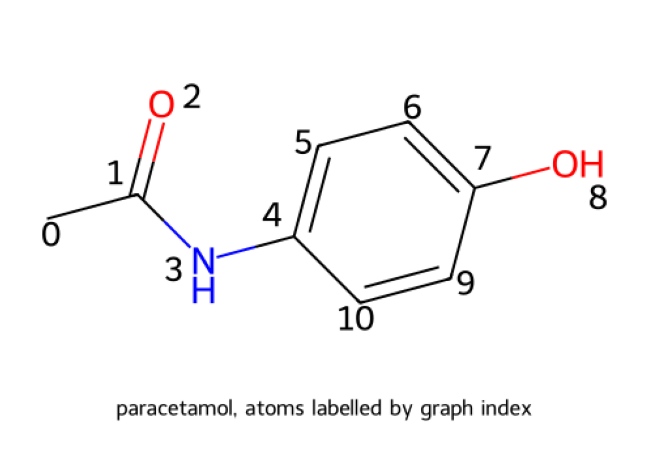

In [2]:
smiles = "CC(=O)Nc1ccc(O)cc1"
mol = Chem.MolFromSmiles(smiles)
print(f"{smiles}  ->  {mol.GetNumAtoms()} heavy atoms, {mol.GetNumBonds()} bonds")
show(draw_molecule_with_indices(mol, size=(480, 330),
                                legend="paracetamol, atoms labelled by graph index"))
plt.show()

Those small numbers are the atom indices. **Every row of `x`, every entry in
`edge_index` and every row of an adjacency matrix refers to these indices.**
Keep the picture next to you while reading the matrices below; without it the
numbers are meaningless.

Hydrogens are implicit. RDKit knows each heavy atom's hydrogen count and we
will put that count *inside* the atom's feature vector rather than adding
hydrogen nodes. Almost all 2-D molecular GNNs do this: explicit hydrogens
roughly double the graph for very little extra signal.

## 1.2 The adjacency matrix

$A_{ij} = 1$ when atoms $i$ and $j$ are bonded, 0 otherwise. For a molecule
this matrix is symmetric, has a zero diagonal (no atom is bonded to itself),
and is extremely sparse — which is exactly why real implementations never
store it.

In [3]:
graph = F.mol_to_graph(mol)
A = F.adjacency_matrix(graph)

labels = [f"{a.GetSymbol()}{a.GetIdx()}" for a in mol.GetAtoms()]
display(pd.DataFrame(A.astype(int), index=labels, columns=labels))

print("symmetric:", np.allclose(A, A.T))
print("zero diagonal:", np.allclose(np.diag(A), 0))
print("non-zero entries:", int(A.sum()), "= 2 x", mol.GetNumBonds(), "bonds")
print("density:", f"{A.sum() / A.size:.1%}")

,C0,C1,O2,N3,C4,C5,C6,C7,O8,C9,C10
C0,0,1,0,0,0,0,0,0,0,0,0
C1,1,0,1,1,0,0,0,0,0,0,0
O2,0,1,0,0,0,0,0,0,0,0,0
N3,0,1,0,0,1,0,0,0,0,0,0
C4,0,0,0,1,0,1,0,0,0,0,1
C5,0,0,0,0,1,0,1,0,0,0,0
C6,0,0,0,0,0,1,0,1,0,0,0
C7,0,0,0,0,0,0,1,0,1,1,0
O8,0,0,0,0,0,0,0,1,0,0,0
C9,0,0,0,0,0,0,0,1,0,0,1


symmetric: True
zero diagonal: True
non-zero entries: 22 = 2 x 11 bonds
density: 18.2%


Read a row and you get an atom's neighbourhood. Row `O2` (the carbonyl oxygen)
has a single 1, in column `C1`. Row `C4` (an aromatic carbon) has three.

The **degree** vector — the row sums — matters more than it looks. It is the
number of messages an atom will receive, and normalising by it is the entire
difference between a GCN and a plain sum aggregation (notebook 03).

In [4]:
degree = F.degree_vector(A)
print(pd.Series(degree.astype(int), index=labels, name="degree").to_string())

C0     1
C1     3
O2     1
N3     2
C4     3
C5     2
C6     2
C7     3
O8     1
C9     2
C10    2


## 1.3 `edge_index`: the sparse form, and why bonds are listed twice

Instead of an $N \times N$ matrix, store only the pairs that exist. Column $k$
of `edge_index` is one directed edge: `edge_index[0, k]` is the **source**
(the atom a message leaves) and `edge_index[1, k]` is the **target** (the atom
it arrives at).

A chemical bond has no direction, but a message does. So every bond appears
**twice**, once each way. If you ever build an edge list by hand and get half
the expected number of columns, this is why — and the symptom is a model that
mysteriously only passes information one way around a ring.

In [5]:
ei = graph.edge_index
print("edge_index shape:", tuple(ei.shape), " (2 rows, one column per directed edge)")
print("bonds in the molecule:", mol.GetNumBonds())
print("directed edges:", ei.shape[1], "=", mol.GetNumBonds(), "x 2")
print()
print("first six columns, read as source -> target:")
for k in range(6):
    s, t = int(ei[0, k]), int(ei[1, k])
    print(f"  column {k}:  {labels[s]:>4s} -> {labels[t]:<4s}")

edge_index shape: (2, 22)  (2 rows, one column per directed edge)
bonds in the molecule: 11
directed edges: 22 = 11 x 2

first six columns, read as source -> target:
  column 0:    C0 -> C1  
  column 1:    C1 -> C0  
  column 2:    C1 -> O2  
  column 3:    O2 -> C1  
  column 4:    C1 -> N3  
  column 5:    N3 -> C1  


Here is the same graph drawn as an abstract node-and-edge diagram, stripped of
chemical drawing conventions. This is what the network actually sees: no ring
geometry, no bond angles, just nodes, edges and feature vectors.

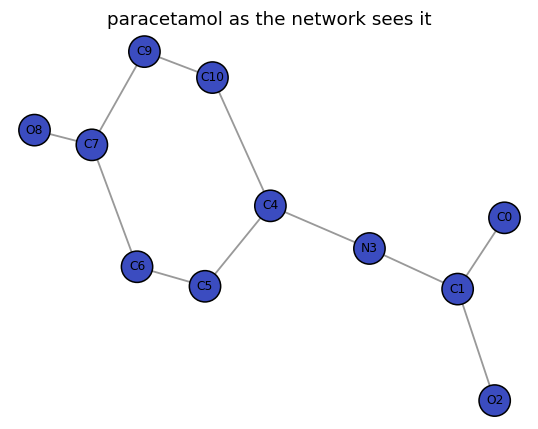

In [6]:
fig = draw_graph_schematic(graph, title="paracetamol as the network sees it")
plt.show()

## 1.4 Atom features: what goes in the vector

Each atom gets a vector built from properties RDKit can compute without a
conformer. In `mgnn.features` the blocks are, in order:

| block | width | why it is there |
|---|---|---|
| element | 13 | a nitrogen is not a carbon; the single most informative feature |
| total degree | 7 | distinguishes a methyl from a quaternary centre |
| formal charge | 6 | an ammonium behaves nothing like an amine |
| attached hydrogens | 6 | carries the implicit H count |
| hybridisation | 6 | sp2 vs sp3 encodes local geometry without coordinates |
| aromatic flag | 1 | cheap, and chemists reason with it constantly |
| in-ring flag | 1 | ring membership changes reactivity and conformational freedom |
| scaled mass | 1 | one continuous feature, to show they are allowed |

Almost everything is **one-hot** rather than numeric. Encoding the element as
atomic number would tell the network that fluorine (9) sits between oxygen (8)
and neon (10) on some meaningful scale, which is false and which the network
would have to waste capacity unlearning.

In [7]:
print("atom feature matrix x:", tuple(graph.x.shape))

atom_idx = 3   # the amide nitrogen, N3
row = graph.x[atom_idx]
active = [(name, float(v)) for name, v in zip(F.ATOM_FEATURE_NAMES, row) if v != 0]
print(f"\nnon-zero features of atom {atom_idx} ({labels[atom_idx]}):")
for name, v in active:
    print(f"  {name:<22s} {v:.3f}")

atom feature matrix x: (11, 41)

non-zero features of atom 3 (N3):
  element=N              1.000
  degree=3               1.000
  charge=0               1.000
  numH=1                 1.000
  hyb=SP2                1.000
  mass*0.01              0.140


Seeing the whole matrix as an image makes the one-hot block structure obvious:
vertical stripes are features shared across atoms, and each horizontal band is
one atom's identity.

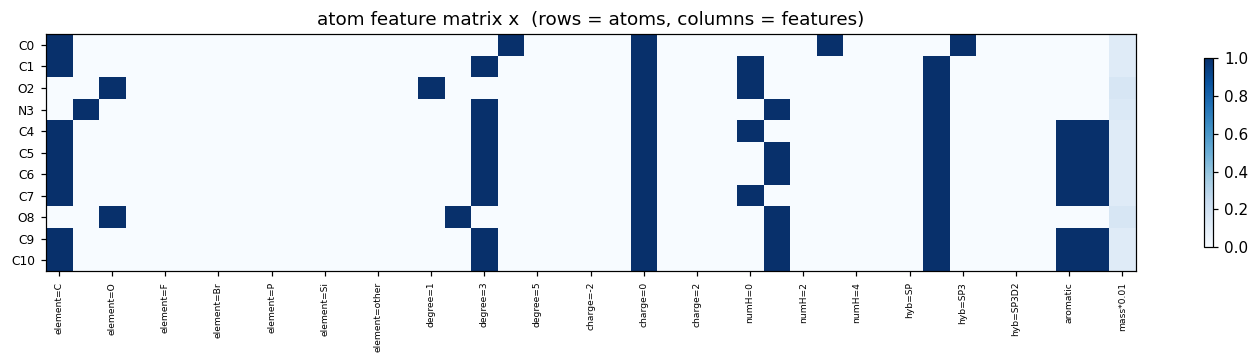

In [8]:
fig, ax = plt.subplots(figsize=(13, 3.4))
im = ax.imshow(graph.x.numpy(), aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.set_xticks(range(0, F.ATOM_FEATURE_DIM, 2),
              [F.ATOM_FEATURE_NAMES[i] for i in range(0, F.ATOM_FEATURE_DIM, 2)],
              rotation=90, fontsize=6)
ax.set_title("atom feature matrix x  (rows = atoms, columns = features)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 1.5 Bond features

Bond order, stereochemistry, conjugation and ring membership. These matter to
the edge-centred layers (D-MPNN in notebook 04); plain GCN and GIN ignore them
entirely, which is worth remembering when a benchmark result looks suspicious —
a model that cannot see bond order cannot distinguish an alkane from an alkene
except through hybridisation and hydrogen counts.

Both directions of a bond carry the **same** feature vector, as the check below
confirms.

In [9]:
print("edge_attr:", tuple(graph.edge_attr.shape))
for k in (0, 1):
    s, t = int(ei[0, k]), int(ei[1, k])
    on = [n for n, v in zip(F.BOND_FEATURE_NAMES, graph.edge_attr[k]) if v != 0]
    print(f"  {labels[s]:>4s} -> {labels[t]:<4s} : {on}")
print("\nthe two directions carry identical features:",
      torch.equal(graph.edge_attr[0], graph.edge_attr[1]))

edge_attr: (22, 12)
    C0 -> C1   : ['bond=SINGLE', 'stereo=STEREONONE']
    C1 -> C0   : ['bond=SINGLE', 'stereo=STEREONONE']

the two directions carry identical features: True


## 1.6 The same code on harder molecules

Teaching examples are always well behaved. Real screening libraries are not,
so check the awkward cases early: a salt (two disconnected fragments), a lone
ion (no bonds at all), a charged centre, a bridged bicycle.

In [10]:
awkward = {
    "salt (two fragments)": "CC(=O)[O-].[Na+]",
    "lone ion (no bonds)": "[Na+]",
    "quaternary ammonium": "C[N+](C)(C)C",
    "bridged bicycle": "C1CC2CCC1CC2",
    "caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
}
rows = []
for name, smi in awkward.items():
    g = F.smiles_to_graph(smi)
    rows.append({"example": name, "smiles": smi, "atoms": g.num_nodes,
                 "directed edges": g.num_edges,
                 "x": str(tuple(g.x.shape)), "edge_attr": str(tuple(g.edge_attr.shape))})
display(pd.DataFrame(rows))

,example,smiles,atoms,directed edges,x,edge_attr
0,salt (two fragments),CC(=O)[O-].[Na+],5,6,"(5, 41)","(6, 12)"
1,lone ion (no bonds),[Na+],1,0,"(1, 41)","(0, 12)"
2,quaternary ammonium,C[N+](C)(C)C,5,8,"(5, 41)","(8, 12)"
3,bridged bicycle,C1CC2CCC1CC2,8,18,"(8, 41)","(18, 12)"
4,caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O,14,30,"(14, 41)","(30, 12)"


The lone sodium ion is the interesting one: `edge_index` is a legitimate but
empty `[2, 0]` tensor. Every layer in `mgnn` is tested against it, because a
library that crashes on `[Na+]` will crash on your screening set at 3 a.m.

A salt is *one graph with two components*. Message passing cannot cross
between the fragments — the sodium never hears about the acetate — and the
readout sums over both. Whether that is what you want is a modelling decision;
many pipelines strip salts first.

In [11]:
salt = F.smiles_to_graph("CC(=O)[O-].[Na+]")
print("salt adjacency (note the isolated last row/column):")
print(F.adjacency_matrix(salt).astype(int))

salt adjacency (note the isolated last row/column):
[[0 1 0 0 0]
 [1 0 1 1 0]
 [0 1 0 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]


## What to take away

* A molecular graph is `x`, `edge_index` and `edge_attr`; everything later in
  this series is a function of those three tensors.
* Atom indices from the drawing, the feature matrix and the adjacency matrix
  are the same indices. Draw the molecule with indices whenever you are
  confused.
* One bond becomes two directed edges.
* One-hot encode categorical chemistry; do not hand the network a false
  ordering.

**Next:** notebook 02 takes a five-atom molecule and walks one message-passing
step through it by hand, printing every intermediate number.